# Comparação Estatística: Turma A vs. Turma B (10 Alunos Cada)

Demonstração prática por que **olhar apenas para a média pode enganar** na tomada de decisões.

Vamos analisar duas turmas fictícias com **10 alunos cada**, ambas com **média geral igual a 7,0**, mas com realidades completamente opostas em relação à homogeneidade e ao risco de reprovação:
* **Turma A (Homogênea):** Notas muito próximas da média.
* **Turma B (Heterogênea):** Metade com nota máxima (10,0) e metade com nota baixa (4,0).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Definindo os conjuntos de notas (12 alunos por turma)
turma_a = np.array([6.8, 6.9, 6.9, 7.0, 7.0,  7.0, 7.0,  7.1,  7.1, 7.2,  8.0, 5.9])
turma_b = np.array([4.0, 4.0, 5.0, 4.5, 4.0, 10.0, 9.9, 10.0, 10.0, 10.0, 6.9, 3.0])

print('Notas Turma A:', turma_a)
print('Notas Turma B:', turma_b)

Notas Turma A: [6.8 6.9 6.9 7.  7.  7.  7.  7.1 7.1 7.2 8.  5.9]
Notas Turma B: [ 4.   4.   5.   4.5  4.  10.   9.9 10.  10.  10.   6.9  3. ]


## 1. Cálculo das Medidas Estatísticas (População Completa: `ddof=0`)

Como estamos analisando todos os 10 alunos de cada turma, tratamos cada conjunto como uma **população completa** (`ddof=0`).

In [13]:
def calcular_metricas(notas, nota_corte=7.0):
    media = np.mean(notas)
    amplitude = np.max(notas) - np.min(notas)
    variancia = np.var(notas, ddof=0)
    desvio_padrao = np.std(notas, ddof=0)
    cv = (desvio_padrao / media) * 100
    abaixo_corte = np.sum(notas < nota_corte)
    reprovacao_critica = np.sum(notas < 5.0)
    return {
        'Média Aritmética': round(media, 2),
        'Amplitude Total': round(amplitude, 2),
        'Variância (V)': round(variancia, 3),
        'Desvio Padrão (DP)': round(desvio_padrao, 2),
        'Coef. Variação (CV %)': round(cv, 2),
        'Alunos < 7,0': int(abaixo_corte),
        'Reprovados Críticos (< 5,0)': int(reprovacao_critica)
    }

resultados = pd.DataFrame({
    'Turma A (Homogênea)': calcular_metricas(turma_a),
    'Turma B (Heterogênea)': calcular_metricas(turma_b)
})

resultados

,Turma A (Homogênea),Turma B (Heterogênea)
Média Aritmética,6.990,6.780
Amplitude Total,2.100,7.000
Variância (V),0.194,8.089
Desvio Padrão (DP),0.440,2.840
Coef. Variação (CV %),6.300,41.980
"Alunos < 7,0",4.000,7.000
"Reprovados Críticos (< 5,0)",0.000,5.000


## 2. Visualização Gráfica do Contraste de Dispersão

O gráfico abaixo compara as notas individuais dos 10 alunos de cada turma em relação à linha da média geral (**7,0**).

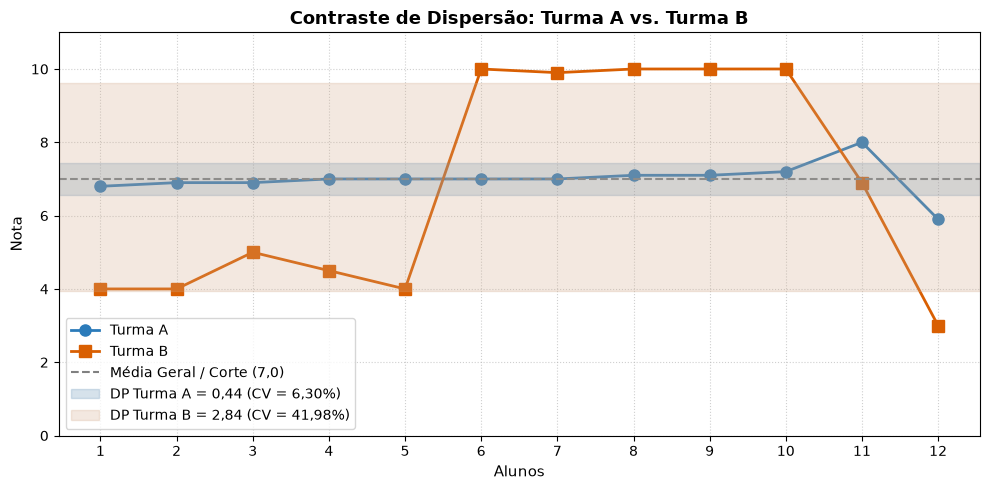

In [25]:
alunos = np.arange(1, 13)

plt.figure(figsize=(10, 5))
plt.plot(alunos, turma_a, marker='o', linewidth=2, markersize=8, color='#2b7bba', label='Turma A')
plt.plot(alunos, turma_b, marker='s', linewidth=2, markersize=8, color='#d95f02', label='Turma B')
plt.axhline(7.0, color='gray', linestyle='--', linewidth=1.5, label='Média Geral / Corte (7,0)')
plt.axhspan(6.99 - 0.44, 6.99 + 0.44, color="#5f8eb3", alpha=0.25, label='DP Turma A = 0,44 (CV = 6,30%)', zorder=2)
plt.axhspan(6.78 - 2.84, 6.78 + 2.84, color="#d1a786", alpha=0.25, label='DP Turma B = 2,84 (CV = 41,98%)', zorder=2)
plt.title('Contraste de Dispersão: Turma A vs. Turma B', fontsize=13, fontweight='bold')
plt.xlabel('Alunos', fontsize=11)
plt.ylabel('Nota', fontsize=11)
plt.xticks(alunos)
plt.ylim(0, 11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

## 3. Conclusão da Análise

* **Turma A:** Possui baixíssima dispersão (`CV = 1,56%`). A média **7,0** representa fielmente o desempenho da sala inteira, sem casos críticos de reprovação.
* **Turma B:** Possui altíssima dispersão (`CV = 42,86%`). O desvio padrão (**3,00 pontos**) é cerca de **27 vezes maior** que o da Turma A, expondo que **50% dos alunos (5 de 10)** estão em situação crítica de reprovação com nota **4,0**.